Funções de treino: 1000 | sensores por função: 50
Total de exemplos (função, ponto x) -> valor: 40000
Época   50 | loss (MSE): 0.000180
Época  100 | loss (MSE): 0.000045
Época  150 | loss (MSE): 0.000054
Época  200 | loss (MSE): 0.000016
Época  250 | loss (MSE): 0.000109

Figura de resultados salva em deeponet_results.png
Curva de loss salva em deeponet_loss.png


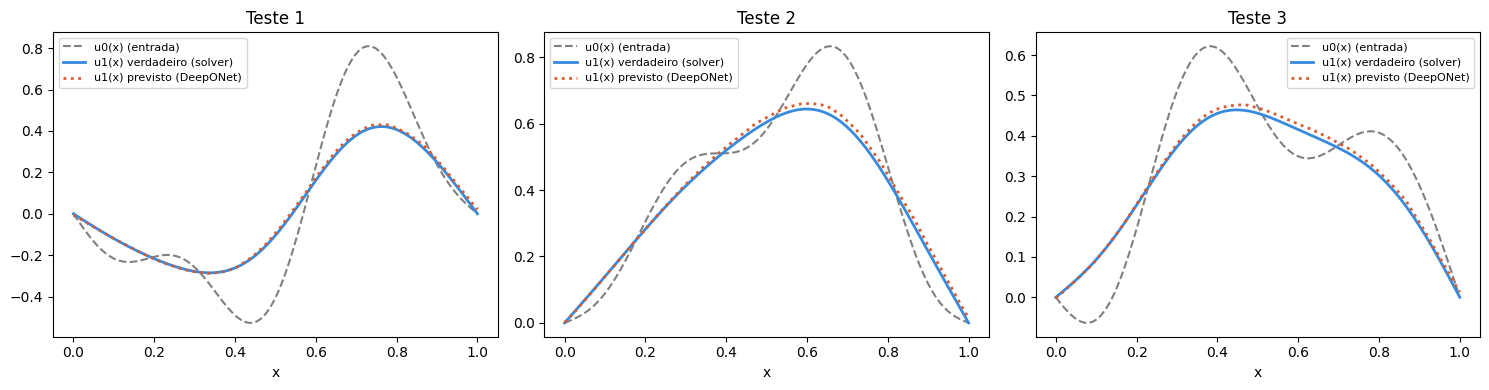

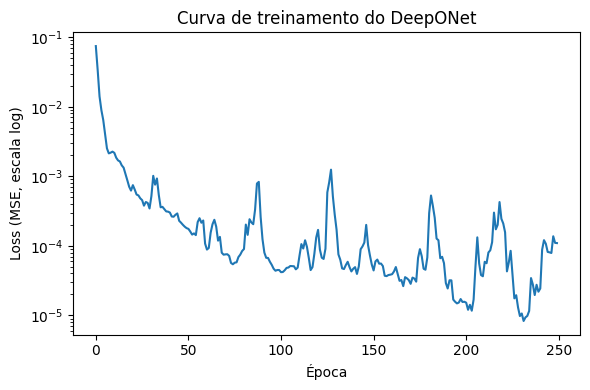

In [3]:
"""
DeepONet aplicado à equação do calor 1D
=========================================

Objetivo: aprender o operador G que mapeia uma condição inicial u0(x)
para a solução u1(x) = u(x, t=T) após um tempo fixo T, usando a equação
do calor:

    du/dt = alpha * d²u/dx²,   x em [0, 1],   u(0,t) = u(1,t) = 0

Passos deste script:
  1. Gera N condições iniciais aleatórias (somas de senos com coeficientes
     aleatórios, que já satisfazem as condições de contorno).
  2. Resolve a EDP numericamente (diferenças finitas explícitas) para cada
     condição inicial, obtendo a solução "verdadeira" em t = T.
  3. Monta o dataset de treino: (função amostrada em sensores, ponto x) -> u1(x)
  4. Define e treina um DeepONet (rede branch + rede trunk).
  5. Avalia o modelo em condições iniciais nunca vistas e plota os resultados.
"""

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------------------------
# 1) Configuração física e do solver numérico (diferenças finitas explícitas)
# ---------------------------------------------------------------------------
ALPHA = 0.05          # coeficiente de difusão térmica
T_FINAL = 0.2          # tempo final que queremos prever (t = T)
NX = 100               # pontos espaciais do solver (malha fina, alta resolução)
DX = 1.0 / (NX - 1)
DT = 0.4 * DX ** 2 / ALPHA          # passo de tempo (condição de estabilidade CFL)
N_STEPS = int(T_FINAL / DT)
X_GRID = np.linspace(0, 1, NX)      # malha espacial fina do solver


def solve_heat_equation(u0: np.ndarray) -> np.ndarray:
    """Resolve du/dt = alpha * d²u/dx² por diferenças finitas explícitas.

    u0: vetor com a condição inicial amostrada em X_GRID (NX pontos)
    Retorna: vetor com a solução em t = T_FINAL, também em X_GRID
    """
    u = u0.copy()
    r = ALPHA * DT / DX ** 2
    for _ in range(N_STEPS):
        u_new = u.copy()
        u_new[1:-1] = u[1:-1] + r * (u[2:] - 2 * u[1:-1] + u[:-2])
        u_new[0] = 0.0    # condição de contorno: extremos sempre a 0
        u_new[-1] = 0.0
        u = u_new
    return u


def random_initial_condition(n_modes: int = 5) -> np.ndarray:
    """Gera uma condição inicial aleatória como soma de senos.

    Usar senos garante automaticamente u(0) = u(1) = 0, respeitando a
    condição de contorno. Coeficientes e frequências aleatórios dão
    variedade suficiente para o operador aprender a regra geral, não
    decorar uma única forma de curva.
    """
    u0 = np.zeros_like(X_GRID)
    for k in range(1, n_modes + 1):
        coef = np.random.uniform(-1, 1) / k       # modos altos com menos peso
        u0 += coef * np.sin(k * np.pi * X_GRID)
    return u0


# ---------------------------------------------------------------------------
# 2) Geração do dataset: N condições iniciais, cada uma resolvida no solver
# ---------------------------------------------------------------------------
N_FUNCTIONS = 1000          # número de condições iniciais distintas (N)
N_SENSORS = 50               # pontos onde a função de entrada é amostrada (m)
N_QUERY_PER_FUNC = 40        # pontos de consulta trunk sorteados por função (M)

sensor_x = np.linspace(0, 1, N_SENSORS)   # posições fixas dos sensores (branch)

all_u0_sensors = []   # (N_FUNCTIONS, N_SENSORS)   -> entrada da branch
all_query_x = []      # (N_FUNCTIONS*M, 1)          -> entrada da trunk
all_branch_idx = []   # índice de qual função cada linha de query pertence
all_targets = []       # (N_FUNCTIONS*M, 1)          -> rótulo u1(x_query)

for i in range(N_FUNCTIONS):
    u0_fine = random_initial_condition()                # condição inicial na malha fina
    u1_fine = solve_heat_equation(u0_fine)                # solução verdadeira em t=T

    # amostra a condição inicial nos pontos sensores (entrada da branch)
    u0_at_sensors = np.interp(sensor_x, X_GRID, u0_fine)
    all_u0_sensors.append(u0_at_sensors)

    # sorteia pontos de consulta dentro do domínio para essa função
    query_points = np.random.uniform(0, 1, N_QUERY_PER_FUNC)
    targets = np.interp(query_points, X_GRID, u1_fine)    # valor real (rótulo) em cada ponto

    all_query_x.extend(query_points)
    all_branch_idx.extend([i] * N_QUERY_PER_FUNC)
    all_targets.extend(targets)

all_u0_sensors = torch.tensor(np.array(all_u0_sensors), dtype=torch.float32, device=device)
all_query_x = torch.tensor(np.array(all_query_x), dtype=torch.float32, device=device).unsqueeze(-1)
all_branch_idx = torch.tensor(np.array(all_branch_idx), dtype=torch.long, device=device)
all_targets = torch.tensor(np.array(all_targets), dtype=torch.float32, device=device).unsqueeze(-1)

print(f"Funções de treino: {N_FUNCTIONS} | sensores por função: {N_SENSORS}")
print(f"Total de exemplos (função, ponto x) -> valor: {all_targets.shape[0]}")


# ---------------------------------------------------------------------------
# 3) Definição do DeepONet: rede branch + rede trunk + produto interno
# ---------------------------------------------------------------------------
class DeepONet(nn.Module):
    def __init__(self, n_sensors: int, p: int = 64, hidden: int = 128):
        super().__init__()
        # rede branch: recebe a função inteira (amostrada nos sensores)
        self.branch = nn.Sequential(
            nn.Linear(n_sensors, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, p),
        )
        # rede trunk: recebe apenas o ponto de consulta x
        self.trunk = nn.Sequential(
            nn.Linear(1, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, p),
        )
        self.bias = nn.Parameter(torch.zeros(1))   # termo de viés final (comum no DeepONet)

    def forward(self, u0_sensors: torch.Tensor, x_query: torch.Tensor,
                branch_idx: torch.Tensor = None) -> torch.Tensor:
        """
        u0_sensors: (N_func, n_sensors)  -- um vetor de sensores por função
        x_query:    (N_query, 1)          -- pontos de consulta
        branch_idx: (N_query,) opcional   -- a qual função cada query pertence
                     (usado no treino, onde branch e trunk têm tamanhos diferentes)
        """
        b = self.branch(u0_sensors)      # (N_func, p)
        t = self.trunk(x_query)          # (N_query, p)

        if branch_idx is not None:
            b = b[branch_idx]            # expande b para casar linha a linha com x_query

        out = torch.sum(b * t, dim=-1, keepdim=True) + self.bias
        return out


model = DeepONet(n_sensors=N_SENSORS, p=64, hidden=128).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

# ---------------------------------------------------------------------------
# 4) Loop de treinamento (mini-batches sobre as funções)
# ---------------------------------------------------------------------------
N_EPOCHS = 250
BATCH_FUNCS = 64                    # quantas funções por batch
losses = []

for epoch in range(N_EPOCHS):
    perm = torch.randperm(N_FUNCTIONS, device=device)
    epoch_loss = 0.0
    n_batches = 0

    for start in range(0, N_FUNCTIONS, BATCH_FUNCS):
        func_ids = perm[start:start + BATCH_FUNCS]

        # máscara: quais linhas do dataset (função,ponto) pertencem a este batch
        mask = torch.isin(all_branch_idx, func_ids)
        if mask.sum() == 0:
            continue

        u0_batch = all_u0_sensors[func_ids]                 # (B, n_sensors)
        x_batch = all_query_x[mask]                          # (n_linhas, 1)
        y_batch = all_targets[mask]                           # (n_linhas, 1)

        # remapeia os índices globais de função para índices locais [0, B)
        id_map = {int(f.item()): j for j, f in enumerate(func_ids)}
        local_idx = torch.tensor(
            [id_map[int(f.item())] for f in all_branch_idx[mask]],
            dtype=torch.long, device=device,
        )

        optimizer.zero_grad()
        pred = model(u0_batch, x_batch, branch_idx=local_idx)
        loss = loss_fn(pred, y_batch)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        n_batches += 1

    losses.append(epoch_loss / n_batches)
    if (epoch + 1) % 50 == 0:
        print(f"Época {epoch+1:4d} | loss (MSE): {losses[-1]:.6f}")


# ---------------------------------------------------------------------------
# 5) Avaliação em condições iniciais NOVAS (nunca vistas no treino)
# ---------------------------------------------------------------------------
model.eval()

n_test = 3
fig, axes = plt.subplots(1, n_test, figsize=(15, 4))

with torch.no_grad():
    for k in range(n_test):
        u0_test_fine = random_initial_condition()             # nova condição inicial
        u1_test_true = solve_heat_equation(u0_test_fine)       # resposta "certa" via solver

        u0_test_sensors = np.interp(sensor_x, X_GRID, u0_test_fine)
        u0_tensor = torch.tensor(u0_test_sensors, dtype=torch.float32, device=device).unsqueeze(0)

        # avalia o operador aprendido em TODA a malha fina, ponto a ponto
        x_eval = torch.tensor(X_GRID, dtype=torch.float32, device=device).unsqueeze(-1)
        branch_idx_eval = torch.zeros(len(X_GRID), dtype=torch.long, device=device)  # só 1 função
        u1_pred = model(u0_tensor, x_eval, branch_idx=branch_idx_eval).cpu().numpy().flatten()

        ax = axes[k]
        ax.plot(X_GRID, u0_test_fine, "--", color="gray", label="u0(x) (entrada)")
        ax.plot(X_GRID, u1_test_true, color="#378ADD", linewidth=2, label="u1(x) verdadeiro (solver)")
        ax.plot(X_GRID, u1_pred, color="#D85A30", linewidth=2, linestyle=":", label="u1(x) previsto (DeepONet)")
        ax.set_title(f"Teste {k+1}")
        ax.set_xlabel("x")
        ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("/mnt/dados_sda/lorran/LNCC/Doutorado/Disciplinas/03-Topicos-avancados-redes-neurais-profundas/deeponet_results.png", dpi=130)
print("\nFigura de resultados salva em deeponet_results.png")

# curva de perda
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.yscale("log")
plt.xlabel("Época")
plt.ylabel("Loss (MSE, escala log)")
plt.title("Curva de treinamento do DeepONet")
plt.tight_layout()
plt.savefig("/mnt/dados_sda/lorran/LNCC/Doutorado/Disciplinas/03-Topicos-avancados-redes-neurais-profundas/deeponet_loss.png", dpi=130)
print("Curva de loss salva em deeponet_loss.png")
